<a href="https://colab.research.google.com/github/Abdoulaye279/Financial-Engineering/blob/main/var-es-sp500/sp500_var_es.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# VaR and Expected Shortfall on the S&P 500

In this project I compute the 1-day Value at Risk (VaR) and Expected Shortfall (ES) at 99% for a position in the S&P 500, with five different models, and I backtest them day by day from 2004 to 2026.

- VaR 99%: the loss that should only be exceeded on 1% of days
- ES 99%: the average loss on the days when the VaR is exceeded

The code is in `risk.py`. I use the same S&P 500 file as in the Black-Scholes project (daily closes since January 2000).

In [ ]:
# in Colab, download the repo first so the code and the data are available
try:
    import google.colab
    !git clone -q https://github.com/Abdoulaye279/Financial-Engineering
    %cd Financial-Engineering/var-es-sp500
except ImportError:
    pass

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from risk import garch_fit, garch_filter, evt_tail, backtest, kupiec, christoffersen

df = pd.read_csv("../black-scholes-sp500/data/sp500.csv")
df["Date"] = pd.to_datetime(df["Date"].str[:10])
prices = df.set_index("Date")["Close"].loc["2000-01-01":]
rets = np.log(prices).diff().dropna()
print(len(rets), "daily returns, from", rets.index[0].date(), "to", rets.index[-1].date())

6761 daily returns, from 2000-01-04 to 2026-11-19


## 1. The models

Each model only uses the last 1000 trading days (about 4 years) to estimate the risk of the next day.

1. Normal: returns are normal, volatility is constant over the window.
2. Historical: no assumption, the VaR is the 1% quantile of the past returns.
3. GARCH: returns are normal but the volatility changes every day with a GARCH(1,1).
4. FHS (filtered historical simulation): GARCH volatility, but the quantile is taken from the past standardised residuals instead of the normal law.
5. GARCH-EVT: GARCH volatility, and the tail of the residuals is modelled with extreme value theory (McNeil and Frey, 2000).

The GARCH(1,1) variance is $\sigma^2_t = \omega + \alpha\, r^2_{t-1} + \beta\, \sigma^2_{t-1}$: a big move yesterday raises today's volatility. I coded the maximum likelihood fit myself (`garch_fit`) and refit it every 250 days.

Parameters on the full period:

In [2]:
omega, a, b = garch_fit(rets.values)
print("alpha:", round(a, 3), " beta:", round(b, 3), " alpha+beta:", round(a + b, 3))
print("long-run annual vol:", round(np.sqrt(omega / (1 - a - b) * 252), 3))
print("half-life of a volatility shock:", round(np.log(0.5) / np.log(a + b)), "days")

alpha: 0.119  beta: 0.862  alpha+beta: 0.981
long-run annual vol: 0.182
half-life of a volatility shock: 36 days


alpha + beta is close to 1, so a volatility shock takes more than a month to fade by half. This is the volatility clustering already seen in the Black-Scholes project.

## 2. Checking the assumptions

The normal model assumes normal returns with a constant volatility. On the 1% quantile:

In [3]:
z_raw = (rets - rets.mean()) / rets.std()
print("normal 1% quantile:    ", round(stats.norm.ppf(0.01), 2))
print("historical 1% quantile:", round(np.quantile(z_raw, 0.01), 2))
print("share of days below -2.33 std devs:", round((z_raw < stats.norm.ppf(0.01)).mean(), 4), "instead of 0.01")

normal 1% quantile:     -2.33
historical 1% quantile: -2.88
share of days below -2.33 std devs: 0.0195 instead of 0.01


The real quantile is much further out (-2.88 instead of -2.33 standard deviations) and the "1% event" actually happens on about 2% of days. So a normal VaR is too small.

What if we first remove the volatility clustering with GARCH? I look at the residuals $z_t = r_t / \sigma_t$:

In [4]:
x = rets.values - rets.mean()
sig = np.sqrt(garch_filter(x, omega, a, b)[:-1])
z = x / sig
print("kurtosis of returns:  ", round(stats.kurtosis(x), 2))
print("kurtosis of residuals:", round(stats.kurtosis(z), 2), "(normal: 0)")
print("Jarque-Bera p-value on residuals:", stats.jarque_bera(z).pvalue)
print("residual 1% quantile:", round(np.quantile(z, 0.01), 2), " normal:", round(stats.norm.ppf(0.01), 2))

kurtosis of returns:   10.64
kurtosis of residuals: 1.77 (normal: 0)
Jarque-Bera p-value on residuals: 9.728994760702225e-264
residual 1% quantile: -2.78  normal: -2.33


GARCH removes a large part of the fat tails (the kurtosis drops a lot) but the residuals are still not normal and their left tail is still heavier than the normal one. That is the reason for models 4 and 5: keep GARCH for the volatility, but do not use the normal law for the tail.

### The EVT part

Extreme value theory says that above a high threshold $u$, the excesses of a loss follow a generalized Pareto distribution (GPD), whatever the original distribution. I take as threshold the 90% quantile of the residual losses, fit the GPD on the 10% largest losses, and get the VaR and ES from the formulas

$$VaR = u + \frac{\beta}{\xi}\left[\left(\frac{1-q}{0.10}\right)^{-\xi} - 1\right] \qquad ES = \frac{VaR + \beta - \xi u}{1-\xi}$$

The advantage over FHS is that the 1% quantile does not depend on the 10 most extreme days of the window only: the whole tail is used to fit a smooth curve. The shape parameter $\xi$ tells how heavy the tail is ($\xi > 0$ means fat tail).

threshold u: 1.27  xi: 0.042  beta: 0.649
EVT VaR and ES of the residuals: [np.float64(2.84), np.float64(3.58)]


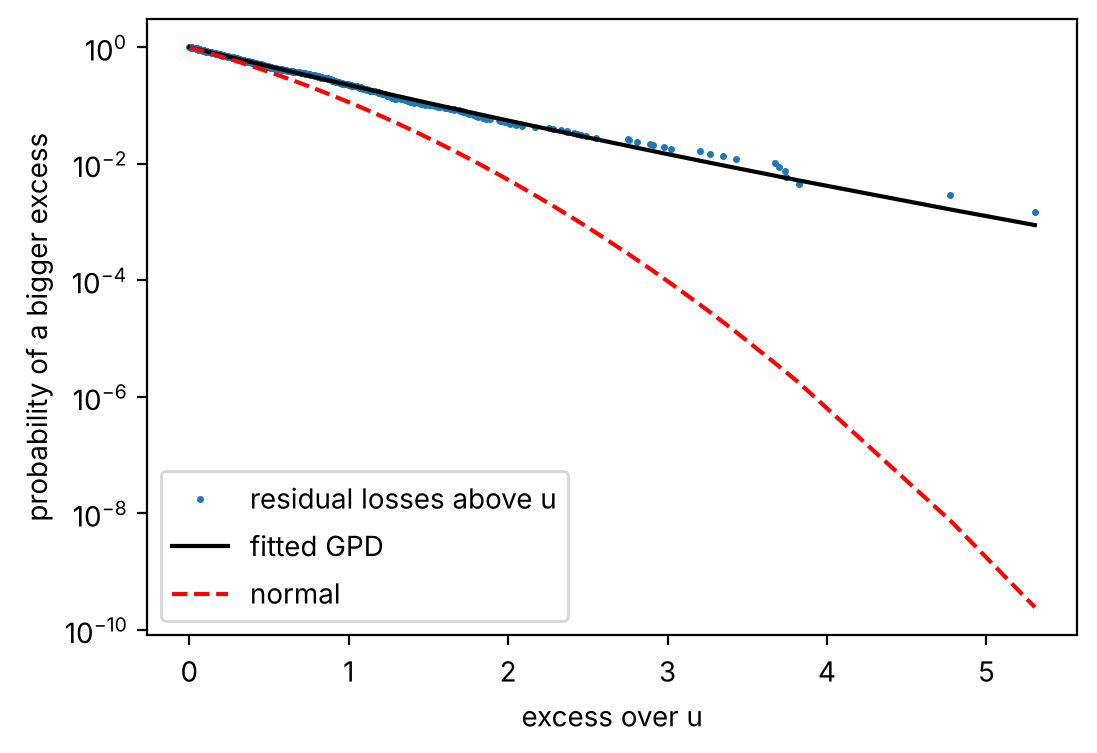

In [5]:
losses = -z
u = np.quantile(losses, 0.9)
excess = losses[losses > u] - u
xi, _, beta = stats.genpareto.fit(excess, floc=0)
print("threshold u:", round(u, 2), " xi:", round(xi, 3), " beta:", round(beta, 3))
print("EVT VaR and ES of the residuals:", [round(v, 2) for v in evt_tail(losses)])

fig, ax = plt.subplots(figsize=(6, 4))
xs = np.sort(excess)
emp = 1 - np.arange(1, len(xs) + 1) / (len(xs) + 1)
ax.plot(xs, emp, ".", ms=3, label="residual losses above u")
ax.plot(xs, stats.genpareto.sf(xs, xi, scale=beta), "k", label="fitted GPD")
ax.plot(xs, stats.norm.sf(xs + u) / stats.norm.sf(u), "r--", label="normal")
ax.set_yscale("log")
ax.set_xlabel("excess over u")
ax.set_ylabel("probability of a bigger excess")
ax.legend()
plt.show()

The GPD follows the tail of the residuals well, while the normal law drops far too fast.

## 3. Backtest

For every day from 2004, each model gives its VaR and ES using only past data. A breach is a day when the real loss is bigger than the VaR, and we expect about 1% of breaches.

I use two tests:
- Kupiec: is the breach rate equal to 1%?
- Christoffersen: are the breaches independent, or does a breach today make a breach tomorrow more likely?

A model is accepted if both p-values are above 5%. I also compare the real average loss on breach days with the predicted ES (1 means the ES is right).

In [6]:
bt = backtest(rets, alpha=0.99, window=1000, refit=250)
models = {"normal": "Normal", "hist": "Historical", "garch": "GARCH", "fhs": "FHS", "evt": "GARCH-EVT"}

print(len(bt), "days tested, expected breaches:", round(0.01 * len(bt)))
print()
for m, name in models.items():
    breach = bt["ret"] < -bt[f"var_{m}"]
    loss = -bt["ret"][breach]
    ratio = loss.mean() / bt[f"es_{m}"][breach].mean()
    print(f"{name:11s} breaches={breach.sum():4d} ({100*breach.mean():.2f}%)  "
          f"Kupiec p={kupiec(breach.values)[1]:.3f}  Christoffersen p={christoffersen(breach.values)[1]:.3f}  "
          f"loss/ES={ratio:.2f}  avg VaR={100*bt[f'var_{m}'].mean():.2f}%")

5761 days tested, expected breaches: 58

Normal      breaches= 135 (2.34%)  Kupiec p=0.000  Christoffersen p=0.000  loss/ES=1.39  avg VaR=2.69%
Historical  breaches=  84 (1.46%)  Kupiec p=0.001  Christoffersen p=0.000  loss/ES=1.07  avg VaR=3.35%
GARCH       breaches= 129 (2.24%)  Kupiec p=0.000  Christoffersen p=0.527  loss/ES=1.12  avg VaR=2.30%
FHS         breaches=  71 (1.23%)  Kupiec p=0.087  Christoffersen p=0.070  loss/ES=1.03  avg VaR=2.74%
GARCH-EVT   breaches=  66 (1.15%)  Kupiec p=0.278  Christoffersen p=0.047  loss/ES=1.03  avg VaR=2.79%


What I get:
- Normal: 2.3% of breaches instead of 1%, and they come in clusters. Both tests reject it, and on breach days the losses are 39% bigger than its ES.
- Historical: closer (1.5%) but still rejected, and the breaches are clustered. A 4-year window reacts much too slowly when a crisis starts.
- GARCH: the breaches are independent now, because the volatility adapts every day, but there are still too many (2.2%) since the normal law underestimates the tail.
- FHS: passes both tests (1.2%, p = 0.09 and 0.07) and its ES is almost exact.
- GARCH-EVT: the breach rate closest to 1% (1.15%, Kupiec p = 0.28) and an exact ES too, but the independence test is at the limit (p = 0.047).

So the volatility and the tail both have to be modelled. FHS and GARCH-EVT give very close results. EVT is better on the breach rate, FHS on independence.

### Breaches over time

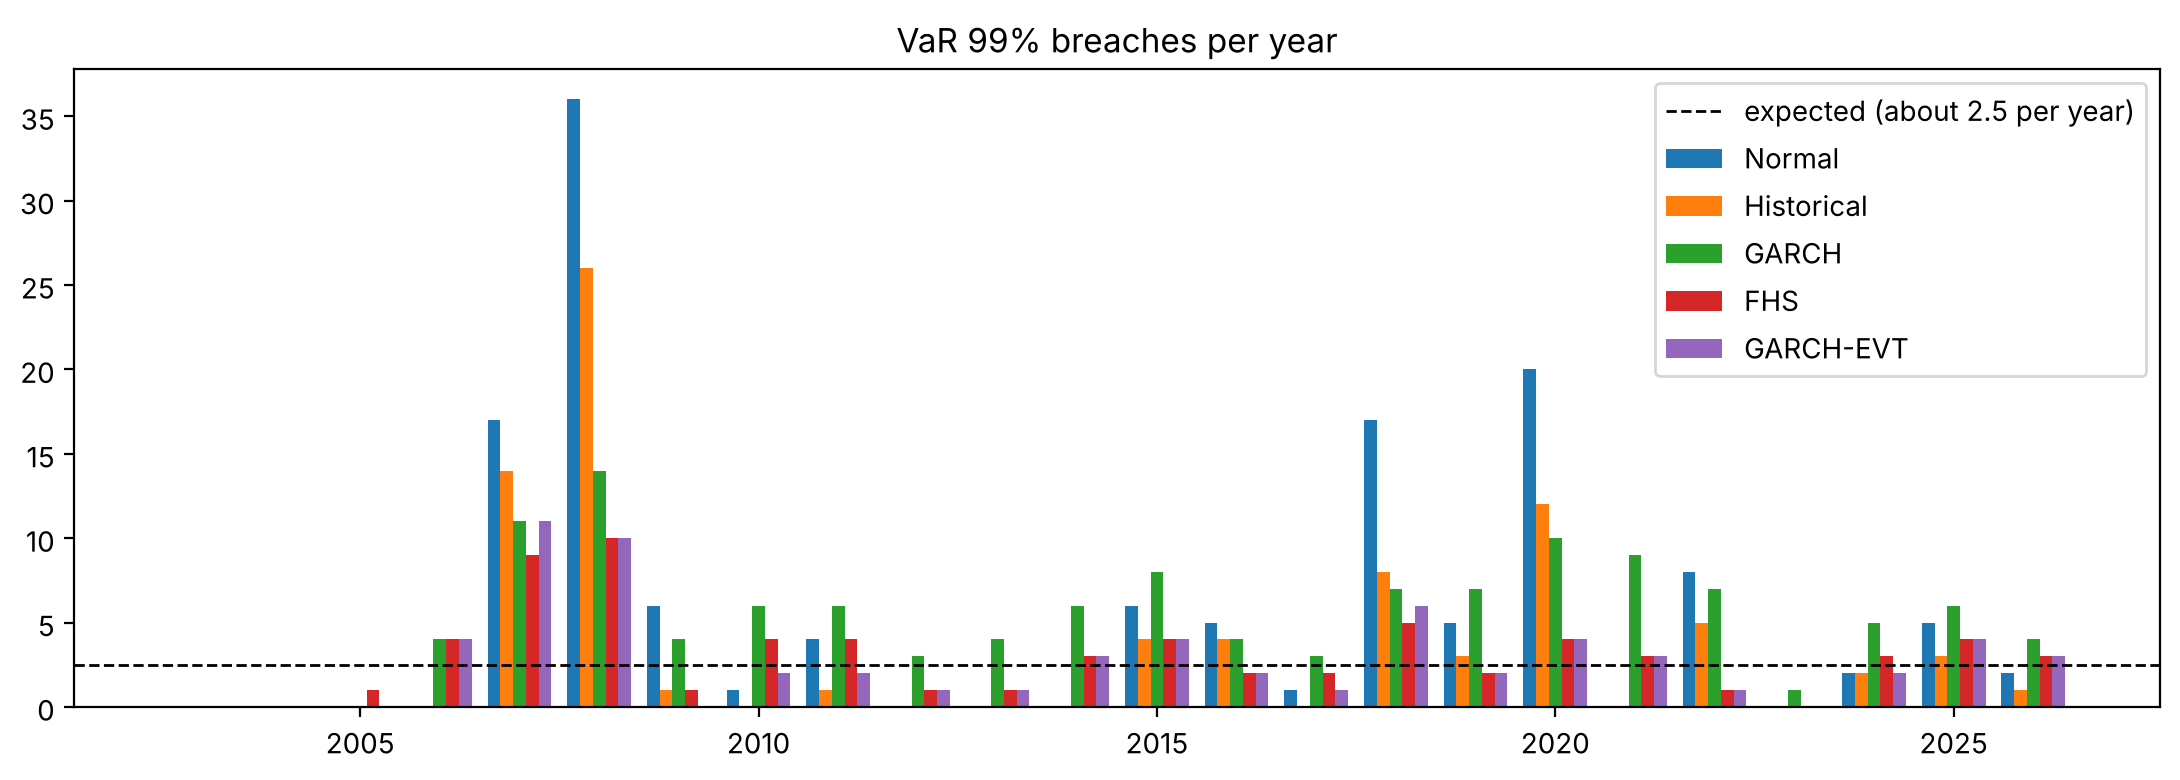

In [7]:
fig, ax = plt.subplots(figsize=(11, 4))
years = sorted(set(bt.index.year))
width = 0.16
for i, (m, name) in enumerate(models.items()):
    per_year = (bt["ret"] < -bt[f"var_{m}"]).groupby(bt.index.year).sum().reindex(years, fill_value=0)
    ax.bar(np.array(years) + (i - 2) * width, per_year, width, label=name)
ax.axhline(2.5, color="k", ls="--", lw=1, label="expected (about 2.5 per year)")
ax.set_title("VaR 99% breaches per year")
ax.legend()
plt.tight_layout()
plt.show()

The normal and historical models fail mostly in 2007-2008, 2018 (the February 2018 volatility spike) and 2020. When a crisis starts, their volatility estimate still contains years of calm market. The three GARCH models spread their breaches much more evenly.

### Zoom on two crises

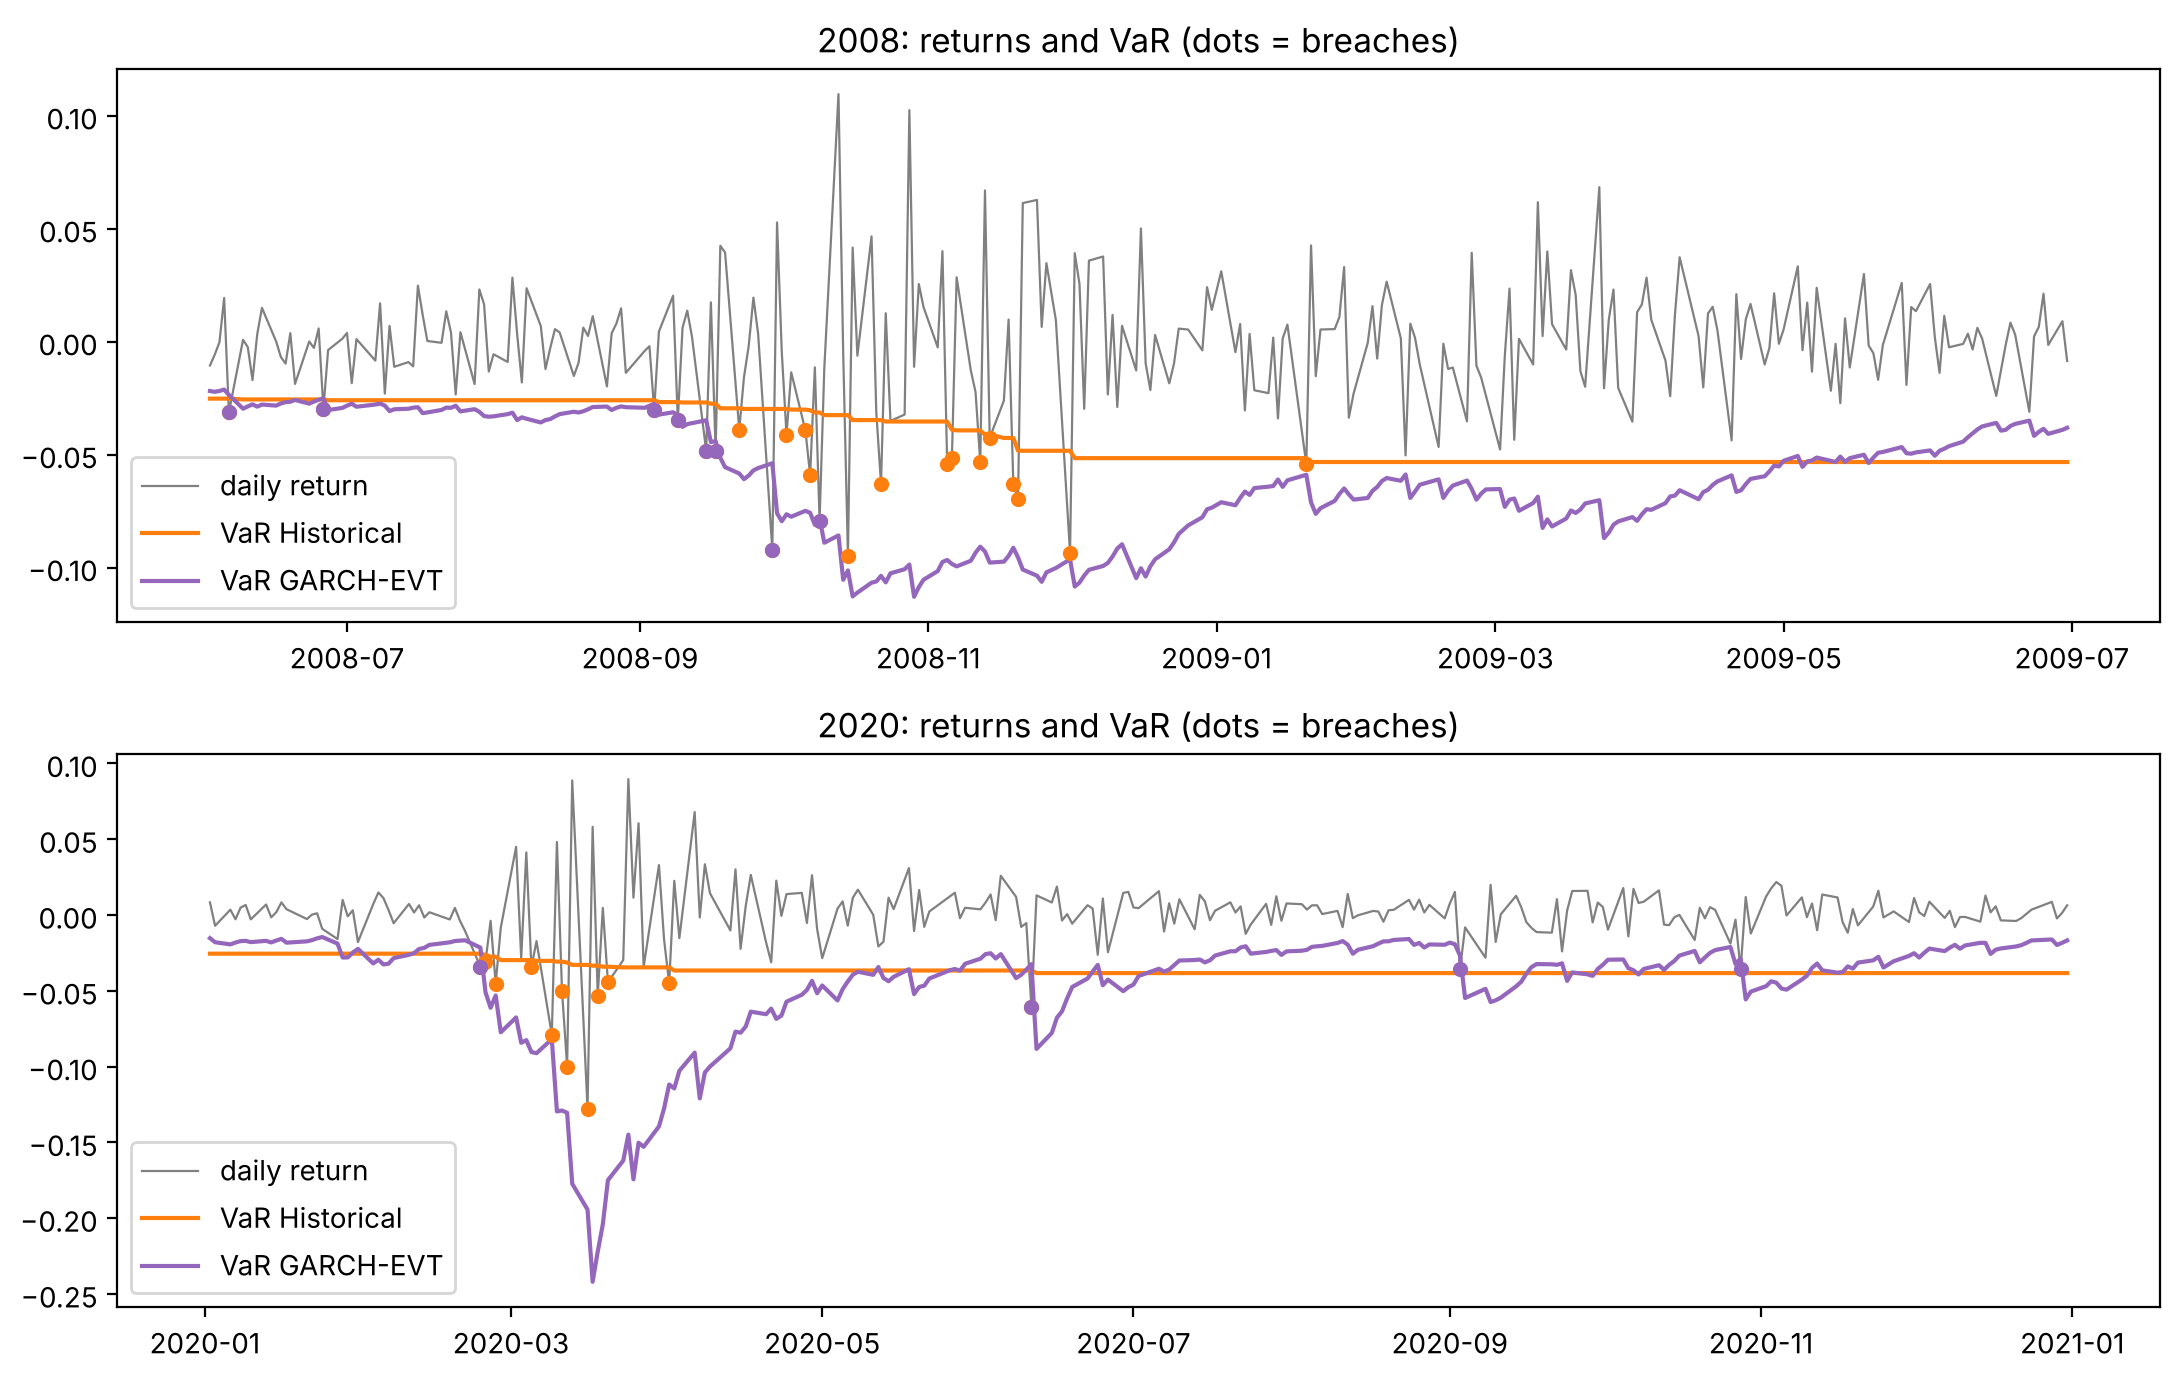

In [8]:
fig, ax = plt.subplots(2, 1, figsize=(11, 7))
for axis, (start, end) in zip(ax, [("2008-06-01", "2009-06-30"), ("2020-01-01", "2020-12-31")]):
    p = bt.loc[start:end]
    axis.plot(p.index, p["ret"], color="grey", lw=0.8, label="daily return")
    for m, color in [("hist", "C1"), ("evt", "C4")]:
        axis.plot(p.index, -p[f"var_{m}"], color=color, label=f"VaR {models[m]}")
        br = p["ret"] < -p[f"var_{m}"]
        axis.scatter(p.index[br], p["ret"][br], color=color, s=20, zorder=3)
    axis.set_title(f"{start[:4]}: returns and VaR (dots = breaches)")
    axis.legend(loc="lower left")
plt.tight_layout()
plt.show()

The historical VaR is almost flat because every day of the last 4 years has the same weight. During the crash it stays too low for weeks and gets breached again and again. The GARCH-EVT VaR widens as soon as volatility goes up, so after the first big losses the breaches stop.

The other side is that GARCH models can overreact: in March 2020 the GARCH-EVT VaR went above 20%, much more than the worst real loss (about 12%). In the opposite way, the historical VaR stays high for years after a crisis, even when markets are calm, which would block too much capital.

## 4. Conclusion

- With normal returns and a constant volatility, the risk is clearly underestimated: 2.3 times more breaches than expected and an ES 39% too small.
- Modelling only the tail (historical) or only the volatility (GARCH normal) is not enough, each one fails a test.
- Combining GARCH with a non-normal tail works: FHS and GARCH-EVT both have a breach rate close to 1% and an almost exact ES.

Limits: one asset, a 1-day horizon, GARCH refitted once a year and a fixed EVT threshold at 10%. Next steps could be a GARCH with Student-t errors or asymmetry (GJR), a 10-day horizon like in the Basel rules, or a portfolio of several assets.